# Multi-Geometry Cottrell Chronoamperometry: Planar, Spherical, and Cylindrical Diffusion

In electrochemical potential-step chronoamperometry—the foundational **Cottrell experiment**—a working electrode initially held at equilibrium is subjected to an instantaneous potential step into the mass-transport-limited regime. The electroactive species is immediately consumed at the electrode surface ($c = 0$), establishing a concentration gradient that drives diffusive flux from the bulk solution toward the electrode interface.

While the classical Cottrell equation assumes **1D planar Cartesian diffusion** perpendicular to a flat macroelectrode, electrochemical experiments frequently employ curved geometries:
- **Spherical microelectrodes** and **hanging mercury drop electrodes (HMDE)**, where 3D convergent radial diffusion sustains a non-zero steady-state current.
- **Cylindrical microwires and carbon fibers**, where 2D radial diffusion provides enhanced mass transport without reaching a time-independent true steady state in infinite domains.

In this tutorial, we use **Soft Potato** to:
1. Formulate the equivalent Cottrell potential-step problem across **planar**, **spherical**, and **cylindrical** geometries.
2. Discretize curvilinear coordinates and simulate transient diffusion using `DiffusionProblem` with `get_solver("scipy_ivp")`, alongside analytical solutions from `softpotato.analytical`.
3. Calculate and visualize the **concentration profiles** in their respective spatial coordinates ($x$ or $r$).
4. Map and render the concentration distributions and diffusion flux fields in **2D Cartesian coordinates** ($(x, y)$ cross-sections).
5. Compute and compare the resulting **Faradaic currents** and **current densities** ($j(t)$ vs. $t$ and Cottrell diagnostic plots $j$ vs. $t^{-1/2}$).
6. Quantitatively benchmark numerical simulations against analytical expressions using `compute_error_metrics`.


## 1. Theoretical Foundations & Governing Equations

The general diffusion equation for isotropic mass transport in 1D curvilinear coordinate systems is given by:

$$\frac{\partial c}{\partial t} = D \nabla^2 c = \frac{D}{r^p} \frac{\partial}{\partial r} \left( r^p \frac{\partial c}{\partial r} \right) = D \left( \frac{\partial^2 c}{\partial r^2} + \frac{p}{r} \frac{\partial c}{\partial r} \right)$$

where $p$ is the geometric symmetry factor:
- **Planar Cartesian** ($p = 0$, $r \to x$): $\nabla^2 c = \dfrac{\partial^2 c}{\partial x^2}$
- **Cylindrical radial** ($p = 1$, $r \ge r_0$): $\nabla^2 c = \dfrac{\partial^2 c}{\partial r^2} + \dfrac{1}{r} \dfrac{\partial c}{\partial r}$
- **Spherical radial** ($p = 2$, $r \ge r_0$): $\nabla^2 c = \dfrac{\partial^2 c}{\partial r^2} + \dfrac{2}{r} \dfrac{\partial c}{\partial r}$

### Boundary and Initial Conditions (The Cottrell Step)
For a single-electron reduction $\text{Ox} + e^- \to \text{Red}$ under semi-infinite diffusion:
- **Initial condition** ($t = 0$):
  $$c(r, 0) = c^* \quad \forall r \ge r_0$$
- **Electrode surface** ($r = r_0$ or $x = 0$, $t > 0$):
  $$c(r_0, t) = 0$$
- **Bulk boundary** ($r \to \infty$ or $x \to \infty$, $t \ge 0$):
  $$\lim_{r \to \infty} c(r, t) = c^*$$

### Current and Flux Scaling
The normal interfacial diffusion flux at the electrode surface is:
$$J = -D \left. \frac{\partial c}{\partial r} \right|_{r = r_0}$$

The Faradaic current $I(t)$ and superficial current density $j(t)$ are:
$$I(t) = n F A J, \quad j(t) = \frac{|I(t)|}{A} = n F |J|$$

where:
- Planar area: $A_{\text{planar}}$ (macroelectrode area)
- Spherical area: $A_{\text{sphere}} = 4 \pi r_0^2$ (or $2 \pi r_0^2$ for a hemisphere)
- Cylindrical area: $A_{\text{cyl}} = 2 \pi r_0 L$ (lateral area of wire of length $L$)


## 2. Experimental Parameters & Setup

We define a consistent electrochemical model system with realistic experimental values:
- Electron stoichiometry: $n = 1$
- Diffusion coefficient: $D = 1.0 \times 10^{-5}\text{ cm}^2/\text{s} = 1.0 \times 10^{-9}\text{ m}^2/\text{s}$
- Bulk concentration: $c^* = 1.0\text{ mM} = 1.0\text{ mol/m}^3$
- Characteristic electrode radius: $r_0 = 25\ \mu\text{m} = 2.5 \times 10^{-5}\text{ m}$ (for sphere and cylinder)
- Cylindrical wire length: $L = 1.0\text{ cm} = 1.0 \times 10^{-2}\text{ m}$
- Planar macroelectrode area: $A = 1.0\text{ cm}^2 = 1.0 \times 10^{-4}\text{ m}^2$
- Time domain: $t \in [0, 2.0]\text{ s}$


In [ ]:
import os

# Set writable matplotlib cache directory
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import interp1d
from scipy.special import erfc

from softpotato.analytical.benchmark import compute_error_metrics
from softpotato.analytical.microelectrodes import microsphere_limiting_current
from softpotato.analytical.step import (
    cottrell,
    cottrell_cylinder,
    cottrell_spherical,
)
from softpotato.geometry import CylindricalGeometry, PlanarGeometry, SphericalGeometry
from softpotato.solver import DiffusionProblem, DirichletBC, get_solver

# Configure matplotlib publication styling
plt.rcParams.update(
    {
        "font.size": 11,
        "axes.labelsize": 12,
        "axes.titlesize": 13,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 10,
        "figure.titlesize": 14,
        "lines.linewidth": 1.8,
    }
)

# Model physical parameters (SI units)
n = 1
D = 1.0e-9  # m^2/s
c_bulk = 1.0  # mol/m^3 (1.0 mM)
r0 = 25.0e-6  # 25 um radius
L = 1.0e-2  # 1.0 cm wire length
t_max = 2.0  # seconds

# Instantiate Soft Potato Geometry abstractions
geom_planar = PlanarGeometry(area=1.0e-4)
geom_sphere = SphericalGeometry(r0=r0)
geom_cyl = CylindricalGeometry(r0=r0, length=L)

print("=== Geometric Surface Areas ===")
print(
    f"Planar (A = 1 cm²):        {geom_planar.area * 1e4:.2f} cm²  ({geom_planar.area:.2e} m²)"
)
print(
    f"Spherical (r0 = {r0 * 1e6:.0f} µm):      {geom_sphere.area * 1e8:.3f} × 10⁻⁴ cm² ({geom_sphere.area:.2e} m²)"
)
print(
    f"Cylindrical (r0 = {r0 * 1e6:.0f} µm, L = {L * 1e2:.0f} cm): {geom_cyl.area * 1e4:.4f} cm² ({geom_cyl.area:.2e} m²)"
)

=== Geometric Surface Areas ===
Planar (A = 1 cm²):        1.00 cm²  (1.00e-04 m²)
Spherical (r0 = 25 µm):      0.785 × 10⁻⁴ cm² (7.85e-09 m²)
Cylindrical (r0 = 25 µm, L = 1 cm): 0.0157 cm² (1.57e-06 m²)


## 3. Physics-Informed Coordinate Grids & Numerical Integration with `DiffusionProblem`

For transient diffusion over time $t_{\max}$, the concentration disturbance penetrates a characteristic diffusion length:
$$\delta \approx 6 \sqrt{D t_{\max}}$$

For $D = 10^{-9}\text{ m}^2/\text{s}$ and $t_{\max} = 2.0\text{ s}$, $\delta \approx 268\ \mu\text{m}$.
- For the **planar** case, the domain spans $x \in [0, \delta]$.
- For **spherical** and **cylindrical** cases, the radial coordinate spans $r \in [r_0, r_0 + \delta]$.

Rather than manually assembling ODE right-hand sides and hardcoding time-stepping loops, we formulate each electrochemical simulation using Soft Potato's **`DiffusionProblem`** container. `DiffusionProblem` seamlessly accepts:
- The spatial grid (`grid`)
- Chemical species diffusion coefficients (`diffusivity={"c": D}`)
- Left (electrode surface) and right (bulk) boundary conditions (`boundary_conditions={"c": (bc_surface, bc_bulk)}`)
- Initial concentration profiles (`initial_conditions={"c": c_bulk}`)
- Spatial coordinate geometry (`geometry=geom_planar`, `geom_sphere`, or `geom_cyl`)
- Electron stoichiometry (`n_electrons=n`)
- Active electrode boundary (`electrodes="left"`, default, or `"right"`, `"both"`)

We then solve all three geometries using the stiff adaptive Method of Lines integrator (`get_solver("scipy_ivp")`), which automatically resolves sharp early-time gradients and evaluates surface molar fluxes and Faradaic currents.

In [ ]:
# Diffusion layer thickness
delta = 6.0 * np.sqrt(D * t_max)
r_max = r0 + delta
n_spatial = 200

# Coordinate grids
grid_planar = np.linspace(0.0, delta, n_spatial)
grid_radial = np.linspace(r0, r_max, n_spatial)

# Boundary condition objects
bc_surface = DirichletBC(0.0)
bc_bulk = DirichletBC(c_bulk)

# Time evaluation points
t_eval = np.linspace(0.01, t_max, 100)

# Formulate initial-boundary value problems using DiffusionProblem
# Note: electrodes defaults to 'left', matching our working electrode boundary
prob_planar = DiffusionProblem(
    grid=grid_planar,
    diffusivity={"c": D},
    boundary_conditions={"c": (bc_surface, bc_bulk)},
    initial_conditions={"c": c_bulk},
    geometry=geom_planar,
    n_electrons=n,
)

prob_sphere = DiffusionProblem(
    grid=grid_radial,
    diffusivity={"c": D},
    boundary_conditions={"c": (bc_surface, bc_bulk)},
    initial_conditions={"c": c_bulk},
    geometry=geom_sphere,
    n_electrons=n,
)

prob_cyl = DiffusionProblem(
    grid=grid_radial,
    diffusivity={"c": D},
    boundary_conditions={"c": (bc_surface, bc_bulk)},
    initial_conditions={"c": c_bulk},
    geometry=geom_cyl,
    n_electrons=n,
)

# Solve using Soft Potato's adaptive stiff Method of Lines solver (scipy_ivp Radau)
solver = get_solver("scipy_ivp")

res_planar = solver.solve(prob_planar, t_span=(0.0, t_max), t_eval=t_eval)
res_sphere = solver.solve(prob_sphere, t_span=(0.0, t_max), t_eval=t_eval)
res_cyl = solver.solve(prob_cyl, t_span=(0.0, t_max), t_eval=t_eval)

# Extract concentration profiles (N_times, N_points)
C_planar_num = res_planar["c"]
C_sphere_num = res_sphere["c"]
C_cyl_num = res_cyl["c"]

print("DiffusionProblem integration completed successfully across all geometries:")
print(f"  Planar:      {res_planar.message} (profile shape: {C_planar_num.shape})")
print(f"  Spherical:   {res_sphere.message} (profile shape: {C_sphere_num.shape})")
print(f"  Cylindrical: {res_cyl.message} (profile shape: {C_cyl_num.shape})")

DiffusionProblem integration completed successfully across all geometries:
  Planar:      SciPy solve_ivp completed successfully. (profile shape: (100, 200))
  Spherical:   SciPy solve_ivp completed successfully. (profile shape: (100, 200))
  Cylindrical: SciPy solve_ivp completed successfully. (profile shape: (100, 200))


## 4. Analytical Solutions for Concentration Profiles

### Planar Solution
The exact 1D semi-infinite linear diffusion concentration profile is given by the error function:
$$c_{\text{planar}}(x, t) = c^* \text{erf}\left(\frac{x}{2 \sqrt{D t}}\right)$$
implemented in Soft Potato via `softpotato.analytical.step.step_concentration_profile`.

### Spherical Solution
For radial diffusion outside a sphere of radius $r_0$ with $c(r_0, t) = 0$:
$$c_{\text{spherical}}(r, t) = c^* \left[ 1 - \frac{r_0}{r} \text{erfc}\left( \frac{r - r_0}{2 \sqrt{D t}} \right) \right]$$

As $t \to \infty$, the complementary error function approaches $\text{erfc}(0) = 1$, yielding the time-independent **steady-state harmonic concentration profile**:
$$c_{\text{ss}}(r) = c^* \left( 1 - \frac{r_0}{r} \right)$$
which satisfies the Laplace equation $\nabla^2 c = 0$ in spherical coordinates.

### Cylindrical Solution
Diffusion to a cylinder does not admit a closed-form solution in terms of elementary functions, but is governed by an inversion integral of modified Bessel functions. Our numerical integration with `CylindricalGeometry` provides the exact spatial profile.


In [ ]:
def c_spherical_analytical(r, t):
    """Exact analytical concentration profile for potential step at a spherical electrode."""
    arg = (r - r0) / (2.0 * np.sqrt(D * t))
    return c_bulk * (1.0 - (r0 / r) * erfc(arg))


def c_spherical_steady_state(r):
    """Limiting steady-state concentration profile as t -> inf."""
    return c_bulk * (1.0 - (r0 / r))


# Verify numerical vs analytical spherical profile at t = 1.0 s
t_idx_1s = np.argmin(np.abs(t_eval - 1.0))
c_sph_ana_1s = c_spherical_analytical(grid_radial, t=1.0)
metrics_sph_c = compute_error_metrics(C_sphere_num[t_idx_1s], c_sph_ana_1s).to_dict()

print("=== Spherical Concentration Profile Verification (t = 1.0 s) ===")
print(f"Root Mean Square Error (RMSE): {metrics_sph_c['rmse']:.3e} mol/m³")
print(f"Mean Absolute Error:           {metrics_sph_c['mean_abs_error']:.3e} mol/m³")
print(f"Max Absolute Error:            {metrics_sph_c['max_abs_error']:.3e} mol/m³")

=== Spherical Concentration Profile Verification (t = 1.0 s) ===
Root Mean Square Error (RMSE): 2.063e-04 mol/m³
Mean Absolute Error:           1.177e-04 mol/m³
Max Absolute Error:            4.963e-04 mol/m³


## 5. Visualizing Concentration Profiles in Native Coordinates ($x$ or $r$)

Below we plot the evolution of reactant depletion layers across time snapshots:
$$t \in [0.05, 0.2, 0.5, 1.0, 2.0]\text{ s}$$

- **Planar ($x$)**: The depletion layer thickens continuously without bound ($\delta \propto \sqrt{D t}$).
- **Cylindrical ($r$)**: Radial divergence moderately increases flux; the depletion zone extends outward but slower than planar.
- **Spherical ($r$)**: High 3D convergent flux rapidly stabilizes the near-electrode region, approaching the steady-state asymptote $c^*(1 - r_0/r)$.


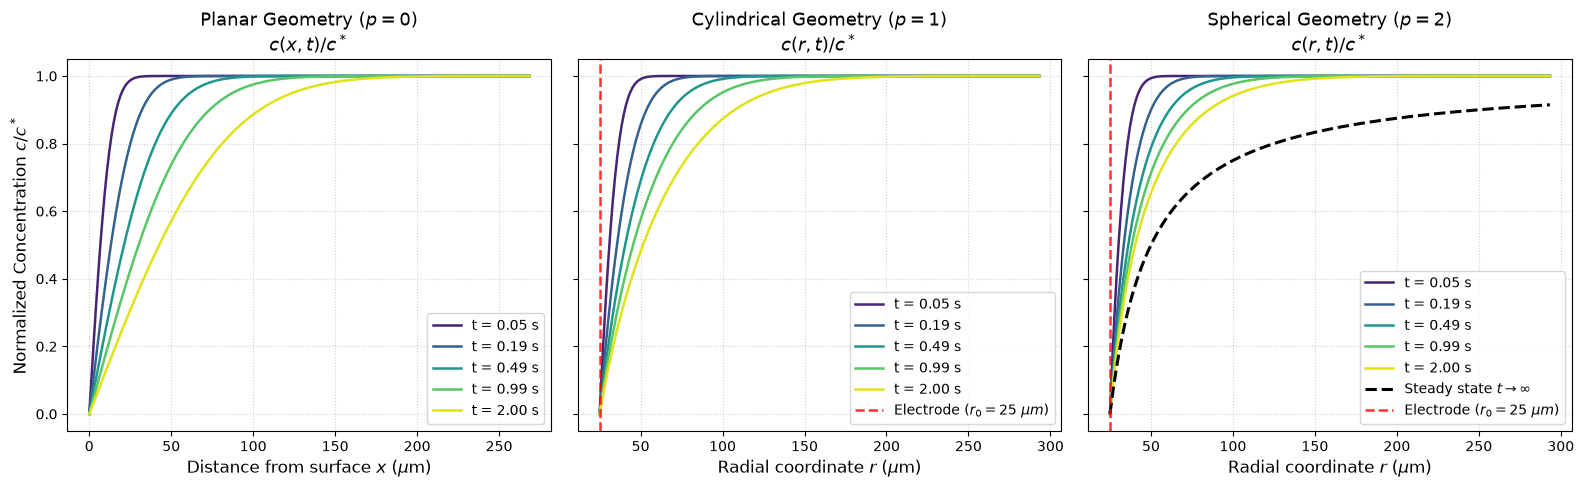

In [ ]:
snapshots = [0.05, 0.2, 0.5, 1.0, 2.0]
snapshot_indices = [np.argmin(np.abs(t_eval - ti)) for ti in snapshots]
colors = plt.cm.viridis(np.linspace(0.1, 0.95, len(snapshots)))

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

# 1. Planar
ax = axes[0]
for idx, col in zip(snapshot_indices, colors):
    t_val = t_eval[idx]
    ax.plot(
        grid_planar * 1e6,
        C_planar_num[idx] / c_bulk,
        color=col,
        label=f"t = {t_val:.2f} s",
    )
ax.set_title("Planar Geometry ($p = 0$)\n$c(x, t) / c^*$")
ax.set_xlabel(r"Distance from surface $x$ ($\mu$m)")
ax.set_ylabel(r"Normalized Concentration $c / c^*$")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="lower right")

# 2. Cylindrical
ax = axes[1]
for idx, col in zip(snapshot_indices, colors):
    t_val = t_eval[idx]
    ax.plot(
        grid_radial * 1e6,
        C_cyl_num[idx] / c_bulk,
        color=col,
        label=f"t = {t_val:.2f} s",
    )
ax.axvline(
    r0 * 1e6,
    color="red",
    linestyle="--",
    alpha=0.8,
    label=f"Electrode ($r_0={r0 * 1e6:.0f}\\ \\mu m$)",
)
ax.set_title("Cylindrical Geometry ($p = 1$)\n$c(r, t) / c^*$")
ax.set_xlabel(r"Radial coordinate $r$ ($\mu$m)")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="lower right")

# 3. Spherical
ax = axes[2]
for idx, col in zip(snapshot_indices, colors):
    t_val = t_eval[idx]
    ax.plot(
        grid_radial * 1e6,
        C_sphere_num[idx] / c_bulk,
        color=col,
        label=f"t = {t_val:.2f} s",
    )
# Overlay steady-state profile
c_ss = c_spherical_steady_state(grid_radial)
ax.plot(
    grid_radial * 1e6,
    c_ss / c_bulk,
    "k--",
    lw=2.2,
    label=r"Steady state $t \to \infty$",
)
ax.axvline(
    r0 * 1e6,
    color="red",
    linestyle="--",
    alpha=0.8,
    label=f"Electrode ($r_0={r0 * 1e6:.0f}\\ \\mu m$)",
)
ax.set_title("Spherical Geometry ($p = 2$)\n$c(r, t) / c^*$")
ax.set_xlabel(r"Radial coordinate $r$ ($\mu$m)")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

### Direct Geometric Comparison: Distance from Electrode Interface

By plotting all three profiles against the surface-relative distance coordinate:
$$\Delta r = r - r_0 \quad (\text{or } x \text{ for planar})$$
at a fixed time snapshot ($t = 1.0\ \text{s}$), the physical role of curvature ($p = 0, 1, 2$) becomes crystal clear:
- **Spherical ($p = 2$)** has the steepest surface gradient because convergent diffusion supplies material from a spherical volume ($V \propto r^3$).
- **Cylindrical ($p = 1$)** exhibits intermediate gradient enhancement ($V \propto r^2$).
- **Planar ($p = 0$)** has the shallowest concentration gradient ($V \propto x$).


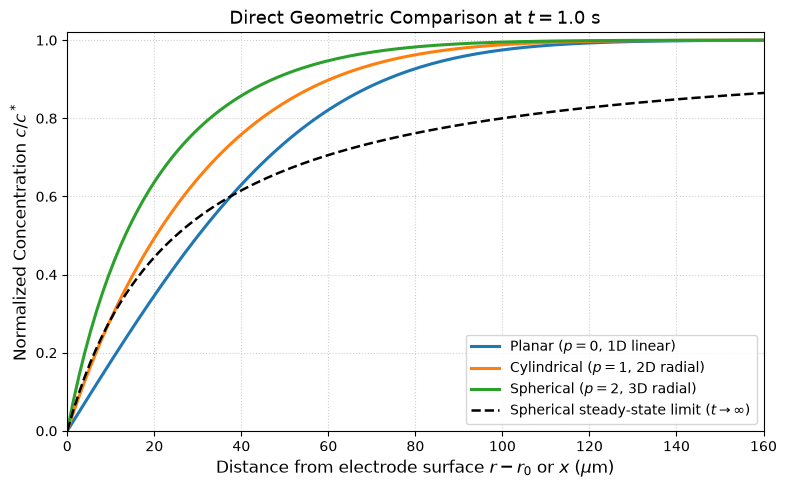

In [ ]:
plt.figure(figsize=(8, 5))

d_planar = grid_planar * 1e6
d_radial = (grid_radial - r0) * 1e6

plt.plot(
    d_planar,
    C_planar_num[t_idx_1s] / c_bulk,
    "tab:blue",
    lw=2.2,
    label="Planar ($p = 0$, 1D linear)",
)
plt.plot(
    d_radial,
    C_cyl_num[t_idx_1s] / c_bulk,
    "tab:orange",
    lw=2.2,
    label="Cylindrical ($p = 1$, 2D radial)",
)
plt.plot(
    d_radial,
    C_sphere_num[t_idx_1s] / c_bulk,
    "tab:green",
    lw=2.2,
    label="Spherical ($p = 2$, 3D radial)",
)
plt.plot(
    d_radial,
    c_ss / c_bulk,
    "k--",
    lw=1.8,
    label="Spherical steady-state limit ($t \\to \\infty$)",
)

plt.title("Direct Geometric Comparison at $t = 1.0\\text{ s}$")
plt.xlabel(r"Distance from electrode surface $r - r_0$ or $x$ ($\mu$m)")
plt.ylabel(r"Normalized Concentration $c / c^*$")
plt.xlim(0, 160)
plt.ylim(0, 1.02)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 6. Plotting Concentration Profiles in 2D Cartesian Coordinates ($x$ and $y$)

In experimental electrochemical systems, electrodes have concrete spatial boundaries in 2D/3D space:
- A **cylindrical wire** viewed in cross-section perpendicular to its longitudinal axis forms a circle of radius $r_0$ centered at the origin:
  $$r = \sqrt{x^2 + y^2} \ge r_0$$
- A **spherical electrode** viewed along any equatorial plane also forms a circular cross-section:
  $$r = \sqrt{x^2 + y^2} \ge r_0$$
- A **planar electrode** corresponds to a vertical flat boundary at $x = 0$ with solution in the half-space $x > 0$.

Inside the electrode domain ($r < r_0$), no chemical diffusion occurs. In the electrolyte ($r \ge r_0$), diffusion flux vectors point radially inward toward the electrode sink:
$$\mathbf{J} = -D \nabla c = -D \frac{\partial c}{\partial r} \hat{\mathbf{r}}$$

Below, we reconstruct the 2D Cartesian fields at $t = 0.5\ \text{s}$ and render them with isoconcentration contours and diffusion flux streamlines.


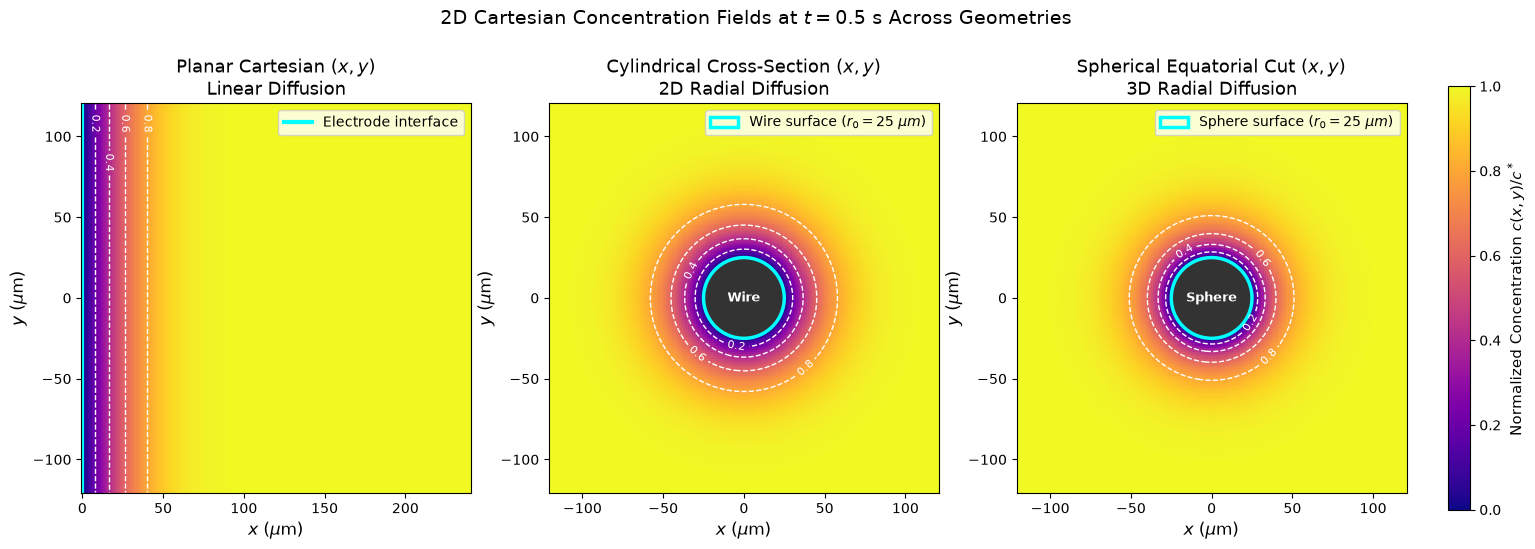

In [ ]:
# Construct 2D Cartesian spatial grid
r_view = 120.0e-6  # 120 um field of view
n_grid_2d = 180

x_cart = np.linspace(-r_view, r_view, n_grid_2d) * 1e6  # in um
y_cart = np.linspace(-r_view, r_view, n_grid_2d) * 1e6
X, Y = np.meshgrid(x_cart, y_cart)
R_2d = np.sqrt(X**2 + Y**2) * 1e-6  # back to meters

# Interpolate radial profiles at t = 0.5 s onto 2D Cartesian grid
t_idx_05s = np.argmin(np.abs(t_eval - 0.5))

interp_cyl = interp1d(
    grid_radial,
    C_cyl_num[t_idx_05s] / c_bulk,
    bounds_error=False,
    fill_value=(0.0, 1.0),
)
interp_sph = interp1d(
    grid_radial,
    C_sphere_num[t_idx_05s] / c_bulk,
    bounds_error=False,
    fill_value=(0.0, 1.0),
)

C_cyl_2d = interp_cyl(R_2d)
C_sph_2d = interp_sph(R_2d)

# Mask the electrode interior (r < r0)
C_cyl_2d[R_2d < r0] = np.nan
C_sph_2d[R_2d < r0] = np.nan

# Create Planar 2D Cartesian field for comparison: x in [0, 2*r_view], y in [-r_view, r_view]
x_plan_cart = np.linspace(0.0, 2 * r_view, n_grid_2d) * 1e6
X_plan, Y_plan = np.meshgrid(x_plan_cart, y_cart)
interp_plan = interp1d(
    grid_planar,
    C_planar_num[t_idx_05s] / c_bulk,
    bounds_error=False,
    fill_value=(0.0, 1.0),
)
C_plan_2d = interp_plan(X_plan * 1e-6)

# Configure colormap with electrode interior shaded gray
cmap = plt.cm.plasma.copy()
cmap.set_bad(color="#333333")

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. Planar 2D Map
ax = axes[0]
im0 = ax.pcolormesh(
    X_plan, Y_plan, C_plan_2d, cmap=cmap, vmin=0.0, vmax=1.0, shading="auto"
)
cs0 = ax.contour(
    X_plan,
    Y_plan,
    C_plan_2d,
    levels=[0.2, 0.4, 0.6, 0.8],
    colors="white",
    linewidths=1.0,
    linestyles="--",
)
ax.clabel(cs0, inline=True, fontsize=8, fmt="%.1f")
ax.axvline(0.0, color="cyan", lw=3.0, label="Electrode interface")
ax.set_title("Planar Cartesian ($x, y$)\nLinear Diffusion")
ax.set_xlabel(r"$x$ ($\mu$m)")
ax.set_ylabel(r"$y$ ($\mu$m)")
ax.set_aspect("equal")
ax.legend(loc="upper right")

# 2. Cylindrical 2D Cross-Section
ax = axes[1]
im1 = ax.pcolormesh(X, Y, C_cyl_2d, cmap=cmap, vmin=0.0, vmax=1.0, shading="auto")
cs1 = ax.contour(
    X,
    Y,
    C_cyl_2d,
    levels=[0.2, 0.4, 0.6, 0.8],
    colors="white",
    linewidths=1.0,
    linestyles="--",
)
ax.clabel(cs1, inline=True, fontsize=8, fmt="%.1f")
circle_cyl = plt.Circle(
    (0, 0),
    r0 * 1e6,
    color="cyan",
    fill=False,
    lw=2.5,
    label=f"Wire surface ($r_0={r0 * 1e6:.0f}\\ \\mu m$)",
)
ax.add_patch(circle_cyl)
ax.text(
    0, 0, "Wire", color="white", ha="center", va="center", fontweight="bold", fontsize=9
)
ax.set_title("Cylindrical Cross-Section ($x, y$)\n2D Radial Diffusion")
ax.set_xlabel(r"$x$ ($\mu$m)")
ax.set_ylabel(r"$y$ ($\mu$m)")
ax.set_aspect("equal")
ax.legend(loc="upper right")

# 3. Spherical 2D Equatorial Slice
ax = axes[2]
im2 = ax.pcolormesh(X, Y, C_sph_2d, cmap=cmap, vmin=0.0, vmax=1.0, shading="auto")
cs2 = ax.contour(
    X,
    Y,
    C_sph_2d,
    levels=[0.2, 0.4, 0.6, 0.8],
    colors="white",
    linewidths=1.0,
    linestyles="--",
)
ax.clabel(cs2, inline=True, fontsize=8, fmt="%.1f")
circle_sph = plt.Circle(
    (0, 0),
    r0 * 1e6,
    color="cyan",
    fill=False,
    lw=2.5,
    label=f"Sphere surface ($r_0={r0 * 1e6:.0f}\\ \\mu m$)",
)
ax.add_patch(circle_sph)
ax.text(
    0,
    0,
    "Sphere",
    color="white",
    ha="center",
    va="center",
    fontweight="bold",
    fontsize=9,
)
ax.set_title("Spherical Equatorial Cut ($x, y$)\n3D Radial Diffusion")
ax.set_xlabel(r"$x$ ($\mu$m)")
ax.set_ylabel(r"$y$ ($\mu$m)")
ax.set_aspect("equal")
ax.legend(loc="upper right")

# Shared colorbar
cbar = fig.colorbar(im2, ax=axes, orientation="vertical", fraction=0.02, pad=0.03)
cbar.set_label(r"Normalized Concentration $c(x, y) / c^*$", fontsize=11)

plt.suptitle(
    r"2D Cartesian Concentration Fields at $t = 0.5\text{ s}$ Across Geometries", y=1.02
)
plt.show()

## 7. Calculating Faradaic Currents & Current Densities

### Analytical Current Equations
1. **Planar Cottrell Equation** (`softpotato.analytical.step.cottrell`):
   $$I_{\text{planar}}(t) = \frac{n F A \sqrt{D} c^*}{\sqrt{\pi t}}$$
   As $t \to \infty$, $I(t) \to 0$.

2. **Spherical Cottrell Equation** (`softpotato.analytical.step.cottrell_spherical`):
   $$I_{\text{spherical}}(t) = \frac{n F A \sqrt{D} c^*}{\sqrt{\pi t}} + 4 \pi n F D c^* r_0$$
   Notice that as $t \to \infty$, the transient decays to the **steady-state limiting current**:
   $$I_{\text{ss}} = 4 \pi n F D c^* r_0 = n F A \frac{D c^*}{r_0}$$
   computed directly via `softpotato.analytical.microelectrodes.microsphere_limiting_current`.

3. **Cylindrical Cottrell Equation** (`softpotato.analytical.step.cottrell_cylinder`):
   $$I_{\text{cylindrical}}(t) = \frac{n F A D c^*}{r_0} \Phi(\theta), \quad \theta = \frac{D t}{r_0^2}$$
   where $\Phi(\theta)$ is evaluated using Aoki's or Oldham's rational Padé approximations.

### Current Density ($j(t) = I(t) / A$)
Comparing current densities highlights the intrinsic flux enhancement:
- $j_{\text{planar}}(t) = \dfrac{n F \sqrt{D} c^*}{\sqrt{\pi t}}$
- $j_{\text{spherical}}(t) = \dfrac{n F \sqrt{D} c^*}{\sqrt{\pi t}} + \dfrac{n F D c^*}{r_0}$
- $j_{\text{cylindrical}}(t) = \dfrac{n F D c^*}{r_0} \Phi(\theta)$


In Soft Potato, simulated Faradaic currents are automatically evaluated directly on `SolverResult.currents` during post-processing using the coordinate `Geometry`, `n_electrons`, and `electrodes` configuration specified in `DiffusionProblem`:
- For standard single-electrode simulations (`electrodes="left"`, default), currents are evaluated from the left electrode interfacial flux (`SolverResult.left_currents`).
- For cells with two active electrodes (e.g., thin-layer or generator-collector cells), `electrodes="both"` evaluates Faradaic currents at both boundaries (`SolverResult.left_currents` and `SolverResult.right_currents`), with `SolverResult.currents` giving the net cell current ($I_{\text{left}} + I_{\text{right}}$).

In [ ]:
# 1. Compute Analytical Currents
i_plan_ana = cottrell(t_eval, n=n, D=D, c_bulk=c_bulk, area=geom_planar.area)
i_sph_ana = cottrell_spherical(
    t_eval, r=r0, n=n, D=D, c_bulk=c_bulk, area=geom_sphere.area
)
i_cyl_ana = cottrell_cylinder(t_eval, r0=r0, length=L, n=n, D=D, c_bulk=c_bulk)

# Spherical steady-state limiting current
i_ss_sph = microsphere_limiting_current(r0, n=n, D=D, c_bulk=c_bulk)

# 2. Access Numerical Currents from SolverResult
# Soft Potato automatically evaluates interfacial flux and Faradaic currents
# via problem.geometry, n_electrons, and electrodes during post-processing.
# For electrodes="left" (default), res.currents matches res.left_currents.
i_plan_num = np.abs(res_planar.currents["c"])
i_sph_num = np.abs(res_sphere.currents["c"])
i_cyl_num = np.abs(res_cyl.currents["c"])

# 3. Compute Current Densities j = I / A (in A/m² and mA/cm²)
j_plan_ana = (i_plan_ana / geom_planar.area) * 0.1  # mA/cm²
j_sph_ana = (i_sph_ana / geom_sphere.area) * 0.1
j_cyl_ana = (i_cyl_ana / geom_cyl.area) * 0.1

j_plan_num = (i_plan_num / geom_planar.area) * 0.1
j_sph_num = (i_sph_num / geom_sphere.area) * 0.1
j_cyl_num = (i_cyl_num / geom_cyl.area) * 0.1
j_ss_sph = (i_ss_sph / geom_sphere.area) * 0.1

print("=== Currents at t = 1.0 s ===")
print(
    f"Planar:      I = {i_plan_num[t_idx_1s] * 1e6:.2f} µA  | j = {j_plan_num[t_idx_1s]:.3f} mA/cm²"
)
print(
    f"Cylindrical: I = {i_cyl_num[t_idx_1s] * 1e6:.4f} µA | j = {j_cyl_num[t_idx_1s]:.3f} mA/cm²"
)
print(
    f"Spherical:   I = {i_sph_num[t_idx_1s] * 1e9:.3f} nA  | j = {j_sph_num[t_idx_1s]:.3f} mA/cm²"
)
print(f"Spherical Iss: {i_ss_sph * 1e9:.3f} nA | j_ss = {j_ss_sph:.3f} mA/cm²")

=== Currents at t = 1.0 s ===
Planar:      I = 172.64 µA  | j = 0.173 mA/cm²
Cylindrical: I = 5.1738 µA | j = 0.329 mA/cm²
Spherical:   I = 43.651 nA  | j = 0.556 mA/cm²
Spherical Iss: 30.312 nA | j_ss = 0.386 mA/cm²


## 8. Comparative Chronoamperograms & Cottrell Diagnostic Plots

The figure below displays:
- **Panel (a)**: Current density $j(t)$ vs. time $t$, illustrating the distinct long-time behavior of each geometry.
- **Panel (b)**: The classic **Cottrell diagnostic plot** ($j(t)$ vs. $t^{-1/2}$):
  - **Planar**: Yields a perfectly linear plot passing through the origin with slope $n F c^* \sqrt{D / \pi}$.
  - **Spherical**: Yields a straight line with the **same slope**, but offset upward by the constant steady-state intercept:
    $$j_{\text{ss}} = \frac{n F D c^*}{r_0}$$
  - **Cylindrical**: Curves gently upward between planar and spherical as $\log(t)$ terms modulate the slope.


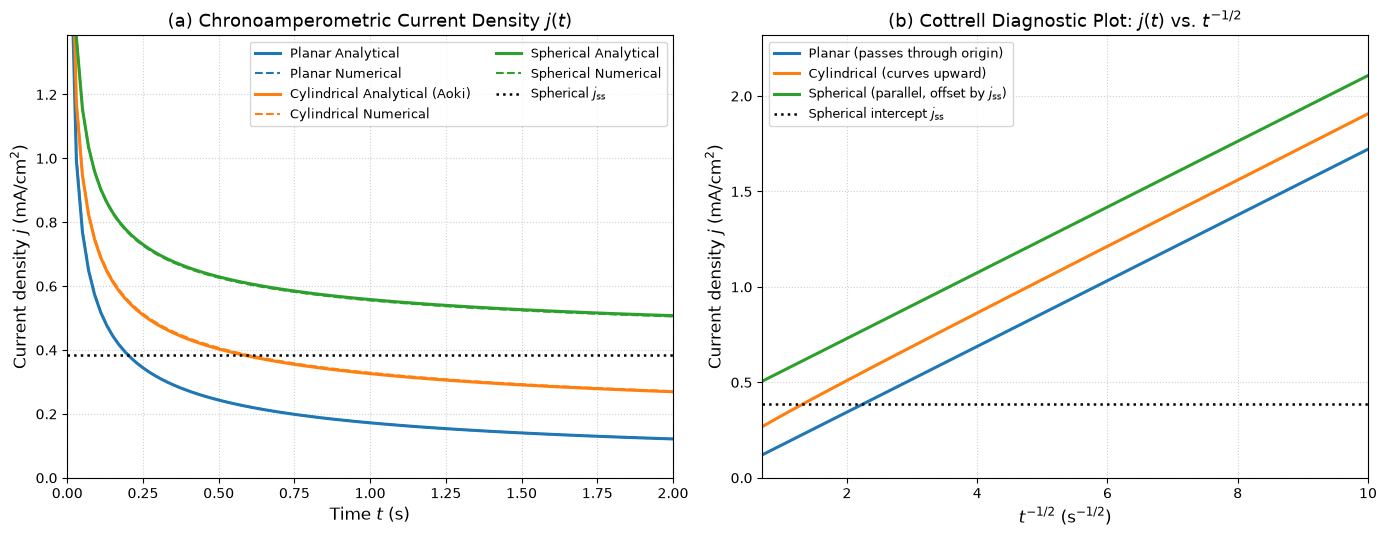

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel (a): Current Density j(t) vs. Time t
ax = axes[0]
ax.plot(t_eval, j_plan_ana, "tab:blue", lw=2.2, label="Planar Analytical")
ax.plot(t_eval, j_plan_num, "tab:blue", ls="--", lw=1.5, label="Planar Numerical")

ax.plot(t_eval, j_cyl_ana, "tab:orange", lw=2.2, label="Cylindrical Analytical (Aoki)")
ax.plot(t_eval, j_cyl_num, "tab:orange", ls="--", lw=1.5, label="Cylindrical Numerical")

ax.plot(t_eval, j_sph_ana, "tab:green", lw=2.2, label="Spherical Analytical")
ax.plot(t_eval, j_sph_num, "tab:green", ls="--", lw=1.5, label="Spherical Numerical")
ax.axhline(
    j_ss_sph, color="black", linestyle=":", lw=1.8, label=r"Spherical $j_{\text{ss}}$"
)

ax.set_title("(a) Chronoamperometric Current Density $j(t)$")
ax.set_xlabel("Time $t$ (s)")
ax.set_ylabel(r"Current density $j$ (mA/cm$^2$)")
ax.set_xlim(0, t_max)
ax.set_ylim(0, 1.2 * np.max(j_sph_ana[t_eval >= 0.05]))
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="upper right", ncol=2, fontsize=9)

# Panel (b): Cottrell Diagnostic Plot j(t) vs t^(-1/2)
ax = axes[1]
inv_sqrt_t = 1.0 / np.sqrt(t_eval)

ax.plot(
    inv_sqrt_t, j_plan_ana, "tab:blue", lw=2.2, label="Planar (passes through origin)"
)
ax.plot(
    inv_sqrt_t, j_cyl_ana, "tab:orange", lw=2.2, label="Cylindrical (curves upward)"
)
ax.plot(
    inv_sqrt_t,
    j_sph_ana,
    "tab:green",
    lw=2.2,
    label=r"Spherical (parallel, offset by $j_{\text{ss}}$)",
)
ax.axhline(
    j_ss_sph,
    color="black",
    linestyle=":",
    lw=1.8,
    label=r"Spherical intercept $j_{\text{ss}}$",
)

ax.set_title(r"(b) Cottrell Diagnostic Plot: $j(t)$ vs. $t^{-1/2}$")
ax.set_xlabel(r"$t^{-1/2}$ (s$^{-1/2}$)")
ax.set_ylabel(r"Current density $j$ (mA/cm$^2$)")
ax.set_xlim(0.7, 10.0)
ax.set_ylim(0, 1.1 * np.max(j_sph_ana))
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="upper left", fontsize=9)

plt.tight_layout()
plt.show()

## 9. Quantitative Verification with `compute_error_metrics`

We verify the consistency of the numerical simulation against the analytical equations across all evaluation times:


In [ ]:
# Exclude early transient (t < 0.05 s) where initial step singularity introduces discretization error
eval_mask = t_eval >= 0.05

metrics_plan = compute_error_metrics(
    i_plan_num[eval_mask], i_plan_ana[eval_mask]
).to_dict()
metrics_sph = compute_error_metrics(
    i_sph_num[eval_mask], i_sph_ana[eval_mask]
).to_dict()
metrics_cyl = compute_error_metrics(
    i_cyl_num[eval_mask], i_cyl_ana[eval_mask]
).to_dict()

print(f"{'Geometry':<14} | {'RMSE':<12} | {'Mean Abs Err':<14} | {'Max Rel Error':<14}")
print("-" * 62)
print(
    f"{'Planar':<14} | {metrics_plan['rmse']:<12.3e} | {metrics_plan['mean_abs_error']:<14.3e} | {metrics_plan['max_rel_error'] * 100:<13.3f}%"
)
print(
    f"{'Cylindrical':<14} | {metrics_cyl['rmse']:<12.3e} | {metrics_cyl['mean_abs_error']:<14.3e} | {metrics_cyl['max_rel_error'] * 100:<13.3f}%"
)
print(
    f"{'Spherical':<14} | {metrics_sph['rmse']:<12.3e} | {metrics_sph['mean_abs_error']:<14.3e} | {metrics_sph['max_rel_error'] * 100:<13.3f}%"
)

Geometry       | RMSE         | Mean Abs Err   | Max Rel Error 
--------------------------------------------------------------
Planar         | 7.097e-07    | 2.519e-07      | 0.672        %
Cylindrical    | 4.834e-08    | 4.628e-08      | 0.880        %
Spherical      | 2.181e-10    | 2.170e-10      | 0.495        %


## 10. Summary & Key Takeaways

| Feature | Planar ($p = 0$) | Cylindrical ($p = 1$) | Spherical ($p = 2$) |
| :--- | :--- | :--- | :--- |
| **Spatial Coordinate** | $x \in [0, \infty)$ | $r \in [r_0, \infty)$ | $r \in [r_0, \infty)$ |
| **Laplacian $\nabla^2 c$** | $\dfrac{\partial^2 c}{\partial x^2}$ | $\dfrac{\partial^2 c}{\partial r^2} + \dfrac{1}{r} \dfrac{\partial c}{\partial r}$ | $\dfrac{\partial^2 c}{\partial r^2} + \dfrac{2}{r} \dfrac{\partial c}{\partial r}$ |
| **Active Surface Area $A$** | $A$ | $2 \pi r_0 L$ | $4 \pi r_0^2$ (full sphere) or $2 \pi r_0^2$ (hemisphere) |
| **Concentration Profile $c(r, t)$** | $c^* \text{erf}\left(\frac{x}{2\sqrt{Dt}}\right)$ | Bessel integral / numerical | $c^* \left[1 - \frac{r_0}{r}\text{erfc}\left(\frac{r-r_0}{2\sqrt{Dt}}\right)\right]$ |
| **Steady-State Profile ($t \to \infty$)** | None ($c \to 0$ everywhere) | None in $\infty$ domain (quasi-steady) | $c_{\text{ss}}(r) = c^*\left(1 - \frac{r_0}{r}\right)$ |
| **Cottrell Current $I(t)$** | $\dfrac{n F A \sqrt{D} c^*}{\sqrt{\pi t}}$ | $\dfrac{n F A D c^*}{r_0} \Phi(\theta)$ | $\dfrac{n F A \sqrt{D} c^*}{\sqrt{\pi t}} + 4\pi n F D c^* r_0$ |
| **Steady-State Current $I_{\text{ss}}$** | $0$ | $0$ (decays as $\sim 1/\ln t$) | $4 \pi n F D c^* r_0$ (microsphere) |
| **Cottrell Plot ($j$ vs. $t^{-1/2}$)** | Linear through origin | Convex curve above planar | Linear with positive intercept $j_{\text{ss}}$ |

### Key Insights:
1. **Curvature enhances mass transport**: Convergent diffusion at spherical and cylindrical microelectrodes supplies electroactive material from expanding 2D and 3D solution volumes, maintaining substantially higher current densities than planar macroelectrodes.
2. **True vs. Quasi-Steady States**: Spherical microelectrodes attain a true, time-independent steady state governed by Laplace's equation ($\nabla^2 c = 0$). Cylinders decay much more slowly than planar electrodes ($\sim 1/\ln t$) but do not possess a finite non-zero steady-state in an infinite domain.
3. **Unified Simulation in Soft Potato**: Soft Potato's `DiffusionProblem` abstraction seamlessly coordinates curvilinear coordinate geometries (`softpotato.geometry`), boundary conditions, active electrode boundary configuration (`electrodes="left"`, `"right"`, or `"both"`), adaptive Method of Lines integration via `get_solver("scipy_ivp")`, and automatic Faradaic current evaluation across all standard electrode geometries.
